# Walk-Forward Evaluation and Leakage Mitigation

This notebook investigates a fundamental problem in financial machine learning: **data leakage** — and its practical remedy through **purging and embargo**.

Three deep-learning classifiers (MLP, LSTM, and CNN-GAF) are trained to predict the 5-day-ahead directional return of Bitcoin.  
The analysis is structured in three stages:

1. **Leakage baseline** — a deliberately flawed single-split evaluation to demonstrate how look-ahead bias inflates apparent accuracy.  
2. **Walk-forward evaluation** — a rolling-window protocol that simulates how a live system would be deployed, removing the leakage from the evaluation loop.  
3. **Purging and embargo** — a stricter variant that additionally drops training observations whose labels overlap with the test window in time, following the methodology of López de Prado (2018).

The goal is not to produce a profitable strategy but to show that model-selection decisions made under leakage are systematically misleading, and that walk-forward + purge/embargo evaluation gives a far more honest estimate of generalisation performance.


## Data Collection and Feature Engineering

Bitcoin daily OHLCV data is downloaded via `yfinance`. Up to 2,000 trading-day observations are retained to keep the experiment tractable. Four raw features (Open, High, Low, Close) are used directly as model inputs; the binary label is whether the 5-day forward return is positive.


In [ ]:
# Dependencies: see requirements.txt
# Models evaluated: MLP, LSTM, CNN-GAF


## Dependencies

All required packages are listed in `requirements.txt`. Key libraries: `tensorflow`, `scikit-learn`, `pyts` (for Gramian Angular Field image encoding), `yfinance`, `pandas`, `numpy`, `matplotlib`.


In [ ]:
# Dependencies: see requirements.txt
# pyts is required for Gramian Angular Field (CNN-GAF) transforms.


## Import libraries


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Dropout, LSTM, Conv2D, MaxPooling2D,
    Flatten
)
from tensorflow.keras.optimizers import Adam

from pyts.image import GramianAngularField

from IPython.display import display


# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("Student: Deginet Fanta Gunta")
print("Deep Learning for Finance")
print("Walk-Forward Evaluation Initialized")


## Market Data and Features


In [ ]:
# Bitcoin is used as the selected security.
# We download daily observations and keep no more than 2,000 rows.

ticker = "BTC-USD"

data = yf.download(
    ticker,
    start="2018-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

# Handle the column format returned by different yfinance versions
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data[["Open", "High", "Low", "Close", "Volume"]].dropna()

# Keep the most recent 2,000 observations
data = data.tail(2000).copy()

print("\nSelected security:", ticker)
print("Number of observations:", len(data))
print("First observation:", data.index.min().date())
print("Last observation:", data.index.max().date())

print("\nThe dataset contains daily open, high, low, closing price and volume information.")
print("Only the latest 2,000 observations are used, which satisfies the assignment limit.")


# Price graph

plt.figure(figsize=(12, 5))
plt.plot(data.index, data["Close"])
plt.title("Bitcoin Daily Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)
plt.tight_layout()
plt.show()


# Return calculation

data["Return"] = data["Close"].pct_change()

plt.figure(figsize=(12, 5))
plt.plot(data.index, data["Return"])
plt.axhline(0, linewidth=1)
plt.title("Bitcoin Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.grid(True)
plt.tight_layout()
plt.show()


# Descriptive statistics

summary = data[["Open", "High", "Low", "Close", "Volume", "Return"]].describe().T

print("\nDescriptive statistics:")
display(summary.round(4))


# Short interpretation

print("\nInterpretation:")
print(
    "The price series shows substantial changes over the sample period, "
    "while daily returns fluctuate around zero with periods of larger movements. "
    "This variation makes the security suitable for testing a return-based trading strategy."
)


## Forward Return Labels and Leakage Setup


In [ ]:
# We predict whether the 5-day future return is positive.
#
# IMPORTANT:
# The train/test split is performed AFTER creating the forward-return labels.
# The last training observations therefore have labels calculated using
# future prices that occur in the test period.
#
# This deliberately creates information leakage between the training

WINDOW = 20
HORIZON = 5

data["Future_Return"] = (
    data["Close"].shift(-HORIZON) / data["Close"] - 1
)

data["Target"] = (data["Future_Return"] > 0).astype(int)

print("\nTarget definition:")
print("Target = 1 if the next 5-day return is positive.")
print("Target = 0 if the next 5-day return is zero or negative.")

print("\nDeliberate leakage:")
print(
    "The forward-return labels are created before the train/test split. "
    "Therefore, training observations close to the split can have labels "
    "that use prices from the future test-period dates."
)


# Check the leakage around split

# We first create the samples.
# Each sample uses the previous 20 daily observations.

feature_columns = ["Open", "High", "Low", "Close", "Volume"]

X_raw = []
y = []
sample_dates = []
future_returns = []

for i in range(WINDOW, len(data) - HORIZON):

    X_raw.append(
        data[feature_columns].iloc[i-WINDOW:i].values
    )

    y.append(data["Target"].iloc[i])
    sample_dates.append(data.index[i])
    future_returns.append(data["Future_Return"].iloc[i])

X_raw = np.array(X_raw)
y = np.array(y)
sample_dates = np.array(sample_dates)
future_returns = np.array(future_returns)

print("\nNumber of usable samples:", len(X_raw))
print("Input window:", WINDOW, "days")
print("Prediction horizon:", HORIZON, "days")


## Single-Split Model Evaluation


In [ ]:
# One chronological 80/20 split is used.

split = int(len(X_raw) * 0.80)

X_train_raw = X_raw[:split]
X_test_raw = X_raw[split:]

y_train = y[:split]
y_test = y[split:]

dates_train = sample_dates[:split]
dates_test = sample_dates[split:]

returns_train = future_returns[:split]
returns_test = future_returns[split:]

print("\nSingle train/test split")
print("-----------------------")
print("Training observations:", len(X_train_raw))
print("Testing observations :", len(X_test_raw))
print("Training period:", dates_train[0], "to", dates_train[-1])
print("Testing period :", dates_test[0], "to", dates_test[-1])


# Show the leakage boundary

boundary_position = split - 1

print("\nLeakage boundary check")
print("----------------------")
print("Last training sample date:", dates_train[-1])
print("Its 5-day forward-return period extends to:",
      pd.Timestamp(dates_train[-1]) + pd.Timedelta(days=HORIZON))

print(
    "\nThis demonstrates the intended leakage: "
    "the final training labels can depend on prices occurring "
    "after the training period and therefore inside the test period."
)


# Scale the input variables

# The scaler is fitted ONLY using training data.
# This prevents additional scaling leakage.

scaler = StandardScaler()

X_train_2d = X_train_raw.reshape(-1, len(feature_columns))
X_test_2d = X_test_raw.reshape(-1, len(feature_columns))

scaler.fit(X_train_2d)

X_train_scaled = scaler.transform(X_train_2d).reshape(
    X_train_raw.shape
)

X_test_scaled = scaler.transform(X_test_2d).reshape(
    X_test_raw.shape
)

print("\nInput variables were standardized using training data only.")


# Model 1: MLP

print("\n==============================")
print("MODEL 1: MLP")
print("==============================")

# Flatten each 20-day input window
X_train_mlp = X_train_scaled.reshape(X_train_scaled.shape[0], -1)
X_test_mlp = X_test_scaled.reshape(X_test_scaled.shape[0], -1)

mlp = Sequential([
    Dense(128, activation="relu", input_shape=(X_train_mlp.shape[1],)),
    Dropout(0.20),
    Dense(64, activation="relu"),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

mlp.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_mlp = mlp.fit(
    X_train_mlp,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    verbose=0
)

mlp_prob = mlp.predict(X_test_mlp, verbose=0).ravel()
mlp_pred = (mlp_prob >= 0.50).astype(int)

mlp_accuracy = accuracy_score(y_test, mlp_pred)

print("MLP test accuracy:", round(mlp_accuracy, 4))


# Model 2: LSTM

print("\n==============================")
print("MODEL 2: LSTM")
print("==============================")

lstm = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(WINDOW, len(feature_columns))),
    Dropout(0.20),
    LSTM(32),
    Dropout(0.20),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_lstm = lstm.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    verbose=0
)

lstm_prob = lstm.predict(X_test_scaled, verbose=0).ravel()
lstm_pred = (lstm_prob >= 0.50).astype(int)

lstm_accuracy = accuracy_score(y_test, lstm_pred)

print("LSTM test accuracy:", round(lstm_accuracy, 4))


# Model 3: CNN based on Gramian Angular Fields

print("\n==============================")
print("MODEL 3: CNN-GAF")
print("==============================")

# For the GAF representation, the closing-price sequence
# from each 20-day window is converted into an image.

gaf = GramianAngularField(
    image_size=WINDOW,
    method="summation"
)

# Use closing price only for the GAF image
close_train = X_train_raw[:, :, 3]
close_test = X_test_raw[:, :, 3]

X_train_gaf = gaf.fit_transform(close_train)
X_test_gaf = gaf.transform(close_test)

# Add image channel
X_train_gaf = X_train_gaf[..., np.newaxis]
X_test_gaf = X_test_gaf[..., np.newaxis]

print("GAF training shape:", X_train_gaf.shape)
print("GAF testing shape :", X_test_gaf.shape)


cnn_gaf = Sequential([
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=X_train_gaf.shape[1:]
    ),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.30),
    Dense(1, activation="sigmoid")
])

cnn_gaf.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_cnn = cnn_gaf.fit(
    X_train_gaf,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    verbose=0
)

cnn_prob = cnn_gaf.predict(X_test_gaf, verbose=0).ravel()
cnn_pred = (cnn_prob >= 0.50).astype(int)

cnn_accuracy = accuracy_score(y_test, cnn_pred)

print("CNN-GAF test accuracy:", round(cnn_accuracy, 4))


# Compare predictive results

accuracy_table = pd.DataFrame({
    "Model": ["MLP", "LSTM", "CNN-GAF"],
    "Test Accuracy": [
        mlp_accuracy,
        lstm_accuracy,
        cnn_accuracy
    ]
})

print("\nTest-set accuracy comparison:")
display(accuracy_table.round(4))


# Confusion matrices

print("\nConfusion matrices")
print("------------------")

print("\nMLP:")
print(confusion_matrix(y_test, mlp_pred))

print("\nLSTM:")
print(confusion_matrix(y_test, lstm_pred))

print("\nCNN-GAF:")
print(confusion_matrix(y_test, cnn_pred))


## Strategy Backtest


In [ ]:
# Trading rule:
# Prediction = 1 -> hold the security
# Prediction = 0 -> stay in cash
#
# The return associated with each test observation is the
# corresponding 5-day forward return.

def backtest_strategy(predictions, realized_returns):

    strategy_returns = np.where(
        predictions == 1,
        realized_returns,
        0.0
    )

    equity_curve = np.cumprod(1 + strategy_returns)

    total_return = equity_curve[-1] - 1

    n = len(strategy_returns)

    # Approximate annualized return using 252 trading days
    annualized_return = (
        equity_curve[-1] ** (252 / n) - 1
    )

    return_series_std = np.std(strategy_returns, ddof=1)

    if return_series_std != 0:
        sharpe = (
            np.mean(strategy_returns) /
            return_series_std
        ) * np.sqrt(252)
    else:
        sharpe = np.nan

    running_max = np.maximum.accumulate(equity_curve)

    drawdown = (
        equity_curve / running_max
    ) - 1

    max_drawdown = drawdown.min()

    return {
        "Total Return": total_return,
        "Annualized Return": annualized_return,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": max_drawdown
    }


# Run the three strategies

mlp_results = backtest_strategy(
    mlp_pred,
    returns_test
)

lstm_results = backtest_strategy(
    lstm_pred,
    returns_test
)

cnn_results = backtest_strategy(
    cnn_pred,
    returns_test
)


# Buy-and-hold benchmark

buy_hold_returns = returns_test

buy_hold_equity = np.cumprod(
    1 + buy_hold_returns
)

buy_hold_total_return = buy_hold_equity[-1] - 1

buy_hold_annualized = (
    buy_hold_equity[-1] ** (252 / len(buy_hold_returns))
    - 1
)

buy_hold_std = np.std(
    buy_hold_returns,
    ddof=1
)

if buy_hold_std != 0:
    buy_hold_sharpe = (
        np.mean(buy_hold_returns) /
        buy_hold_std
    ) * np.sqrt(252)
else:
    buy_hold_sharpe = np.nan

buy_hold_running_max = np.maximum.accumulate(
    buy_hold_equity
)

buy_hold_drawdown = (
    buy_hold_equity /
    buy_hold_running_max
) - 1

buy_hold_max_drawdown = buy_hold_drawdown.min()


# Backtest results table

backtest_table = pd.DataFrame({
    "Strategy": [
        "MLP",
        "LSTM",
        "CNN-GAF",
        "Buy and Hold"
    ],

    "Total Return": [
        mlp_results["Total Return"],
        lstm_results["Total Return"],
        cnn_results["Total Return"],
        buy_hold_total_return
    ],

    "Annualized Return": [
        mlp_results["Annualized Return"],
        lstm_results["Annualized Return"],
        cnn_results["Annualized Return"],
        buy_hold_annualized
    ],

    "Sharpe Ratio": [
        mlp_results["Sharpe Ratio"],
        lstm_results["Sharpe Ratio"],
        cnn_results["Sharpe Ratio"],
        buy_hold_sharpe
    ],

    "Maximum Drawdown": [
        mlp_results["Maximum Drawdown"],
        lstm_results["Maximum Drawdown"],
        cnn_results["Maximum Drawdown"],
        buy_hold_max_drawdown
    ]
})

print("\nBacktest results:")
display(
    backtest_table.style.format({
        "Total Return": "{:.2%}",
        "Annualized Return": "{:.2%}",
        "Sharpe Ratio": "{:.3f}",
        "Maximum Drawdown": "{:.2%}"
    })
)


# Cumulative strategy performance graph

mlp_strategy_returns = np.where(
    mlp_pred == 1,
    returns_test,
    0.0
)

lstm_strategy_returns = np.where(
    lstm_pred == 1,
    returns_test,
    0.0
)

cnn_strategy_returns = np.where(
    cnn_pred == 1,
    returns_test,
    0.0
)

mlp_equity = np.cumprod(
    1 + mlp_strategy_returns
)

lstm_equity = np.cumprod(
    1 + lstm_strategy_returns
)

cnn_equity = np.cumprod(
    1 + cnn_strategy_returns
)


plt.figure(figsize=(12, 6))

plt.plot(
    dates_test,
    mlp_equity,
    label="MLP"
)

plt.plot(
    dates_test,
    lstm_equity,
    label="LSTM"
)

plt.plot(
    dates_test,
    cnn_equity,
    label="CNN-GAF"
)

plt.plot(
    dates_test,
    buy_hold_equity,
    label="Buy and Hold",
    linestyle="--"
)

plt.title(
    "Cumulative Performance of Trading Strategies"
)

plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Training loss graphs

plt.figure(figsize=(10, 5))

plt.plot(
    history_mlp.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_mlp.history["val_loss"],
    label="Validation Loss"
)

plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN-GAF Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Initial Results


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 3.7 MB/s eta 0:00:00
Student: Deginet Fanta Gunta
MScFE 642 - Deep Learning for Finance
Group Work Project #2 - Step 1

Selected security: BTC-USD
Number of observations: 2000
First observation: 2020-07-11
Last observation: 2025-12-31

The dataset contains daily open, high, low, closing price and volume information.
Only the latest 2,000 observations are used, which satisfies the assignment limit.


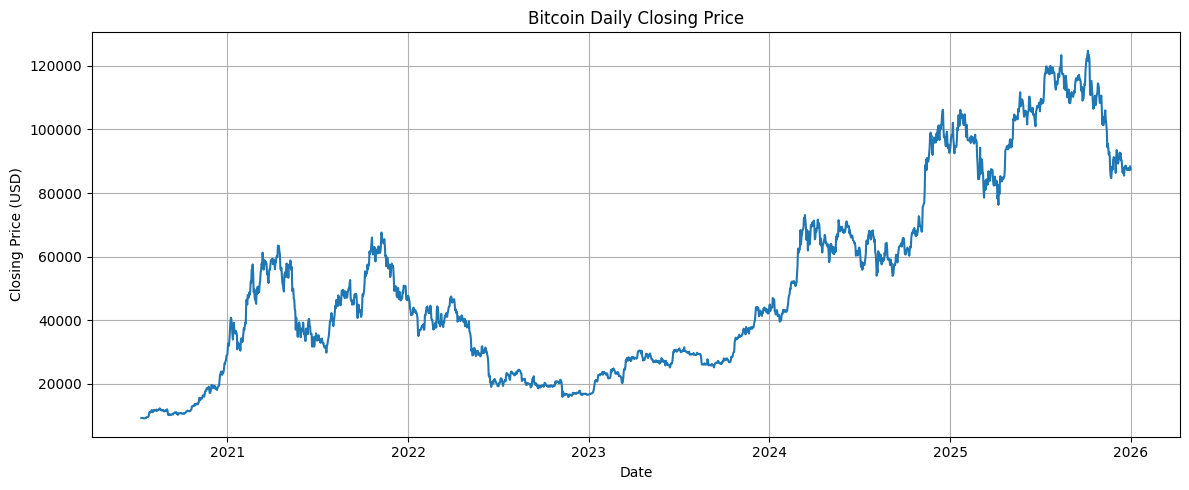

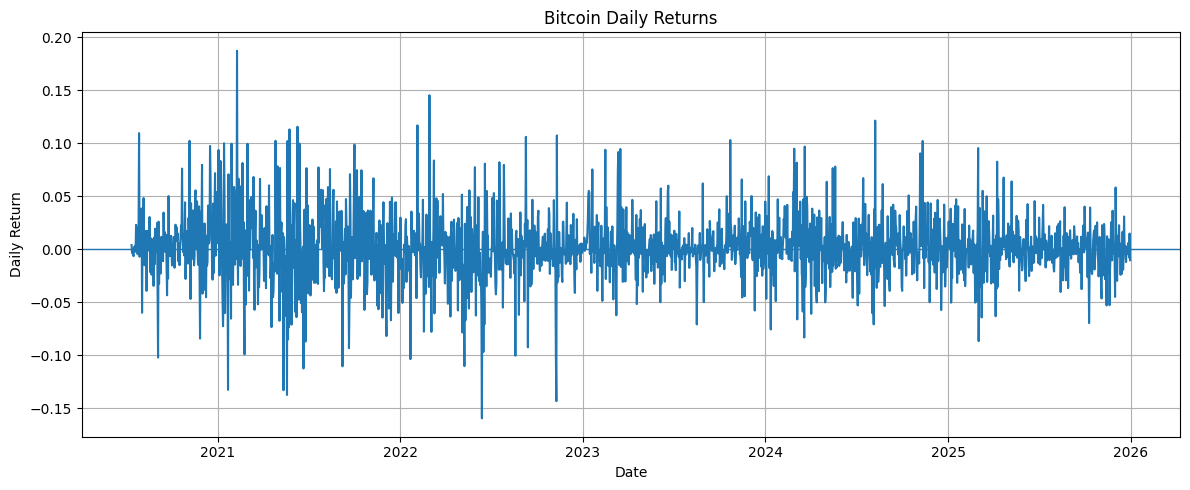


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Open,2000.0,5.087186e+04,3.040564e+04,9.131812e+03,2.669916e+04,4.288546e+04,6.704840e+04,1.247521e+05
High,2000.0,5.187067e+04,3.084765e+04,9.182254e+03,2.708276e+04,4.373670e+04,6.821103e+04,1.261981e+05
Low,2000.0,4.981912e+04,2.992689e+04,9.088947e+03,2.632696e+04,4.205360e+04,6.576840e+04,1.231960e+05
Close,2000.0,5.090897e+04,3.040239e+04,9.132228e+03,2.674519e+04,4.289185e+04,6.707982e+04,1.247525e+05
Volume,2000.0,3.670609e+10,2.235161e+10,5.331173e+09,2.162606e+10,3.158629e+10,4.605740e+10,3.509679e+11
Return,1999.0,1.600000e-03,3.050000e-02,-1.597000e-01,-1.280000e-02,6.000000e-04,1.510000e-02,1.875000e-01



Interpretation:
The price series shows substantial changes over the sample period, while daily returns fluctuate around zero with periods of larger movements. This variation makes the security suitable for testing a return-based trading strategy.

Target definition:
Target = 1 if the next 5-day return is positive.
Target = 0 if the next 5-day return is zero or negative.

Deliberate leakage:
The forward-return labels are created before the train/test split. Therefore, training observations close to the split can have labels that use prices from the future test-period dates.

Number of usable samples: 1975
Input window: 20 days
Prediction horizon: 5 days

Single train/test split
-----------------------
Training observations: 1580
Testing observations : 395
Training period: 2020-07-31 00:00:00 to 2024-11-26 00:00:00
Testing period : 2024-11-27 00:00:00 to 2025-12-26 00:00:00

Leakage boundary check
----------------------
Last training sample date: 2024-11-26 00:00:00
Its 5-day forward-re

,Model,Test Accuracy
0,MLP,0.4835
1,LSTM,0.4734
2,CNN-GAF,0.5013



Confusion matrices
------------------

MLP:
[[179   8]
 [196  12]]

LSTM:
[[186   1]
 [207   1]]

CNN-GAF:
[[ 99  88]
 [109  99]]

Backtest results:


,Strategy,Total Return,Annualized Return,Sharpe Ratio,Maximum Drawdown
0,MLP,-1.73%,-1.11%,-0.072,-11.84%
1,LSTM,-0.40%,-0.25%,-0.017,-5.05%
2,CNN-GAF,-15.91%,-10.46%,0.019,-60.00%
3,Buy and Hold,-38.04%,-26.32%,-0.077,-83.08%


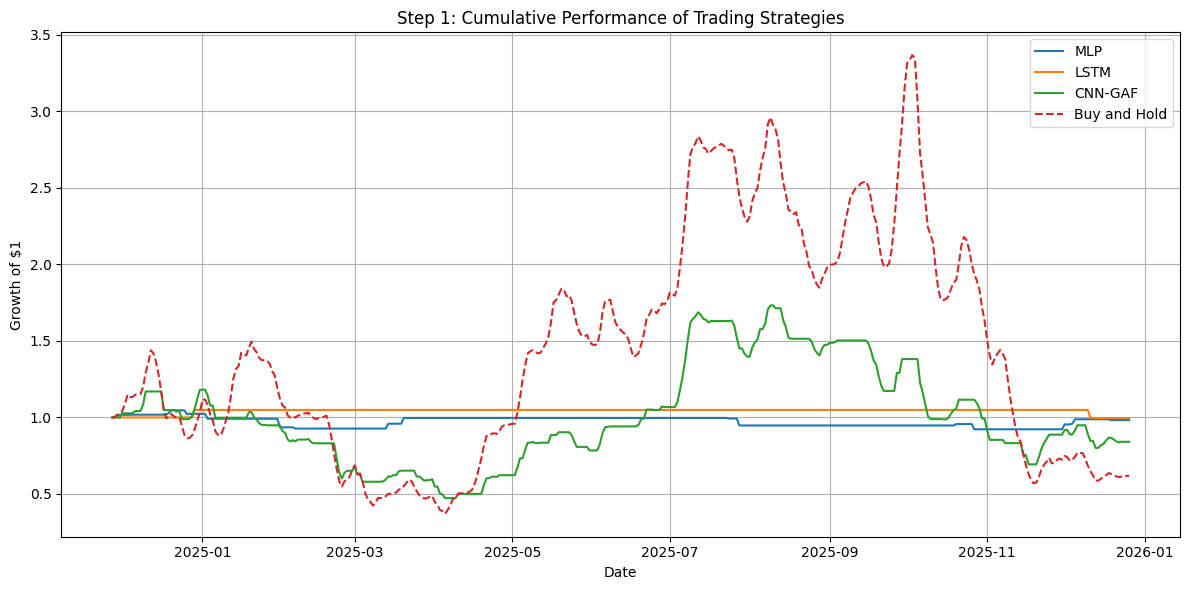

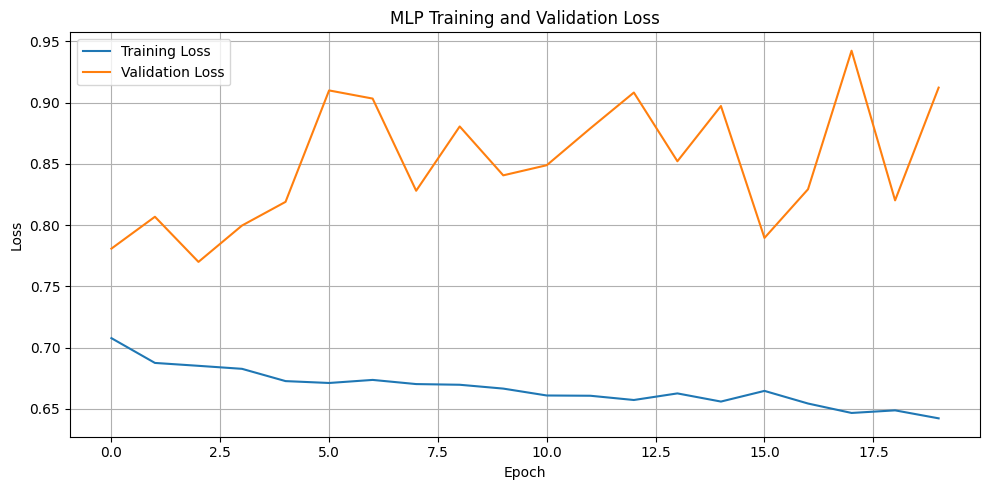

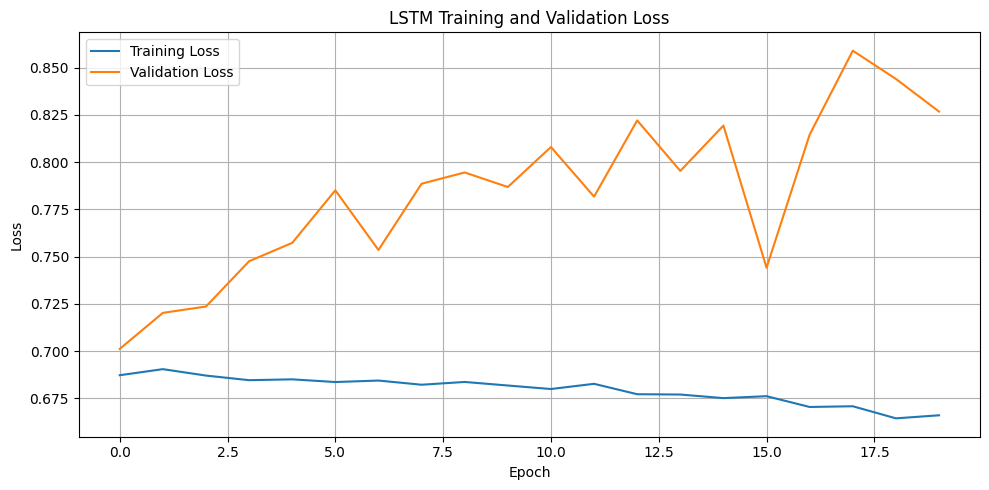

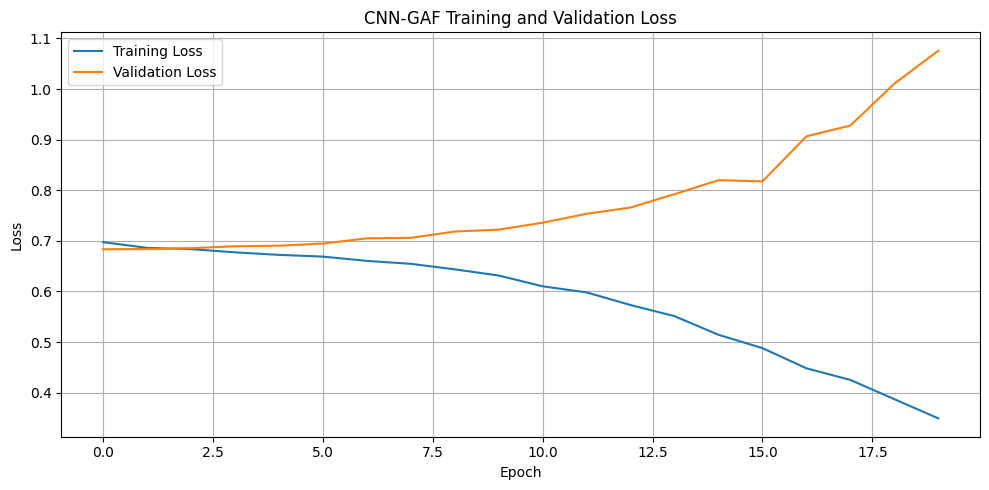


STEP 1 INTERPRETATION
The test-set accuracy comparison shows that CNN-GAF has the highest classification accuracy among the three models.
In the backtest, LSTM produces the highest total return among the three model-based strategies.
The strategies should not be interpreted as evidence of reliable out-of-sample performance because the experiment deliberately contains information leakage in the labels.
In particular, observations near the train/test boundary can have training labels calculated using future prices that extend into the test period. This can make the backtest performance look better than it would under a properly separated validation procedure.

Step 1 establishes the intentionally leaky benchmark. The later walk-forward procedures in Steps 2 and 3 can then be used to examine whether the apparent performance remains robust.

Step 1 completed by Deginet Fanta Gunta.
Next: Step 2 will use non-anchored walk-forward validation.


In [1]:
best_accuracy_model = accuracy_table.loc[
    accuracy_table["Test Accuracy"].idxmax(),
    "Model"
]

best_return_model = backtest_table.iloc[
    backtest_table["Total Return"].iloc[:3].idxmax()
]["Strategy"]

print("\n================================================")
print("STEP 1 INTERPRETATION")
print("================================================")

print(
    f"The test-set accuracy comparison shows that {best_accuracy_model} "
    "has the highest classification accuracy among the three models."
)

print(
    f"In the backtest, {best_return_model} produces the highest total "
    "return among the three model-based strategies."
)

print(
    "The strategies should not be interpreted as evidence of reliable "
    "out-of-sample performance because the experiment deliberately "
    "contains information leakage in the labels."
)

print(
    "In particular, observations near the train/test boundary can have "
    "training labels calculated using future prices that extend into the "
    "test period. This can make the backtest performance look better than "
    "it would under a properly separated validation procedure."
)

print(
    "\nStep 1 establishes the intentionally leaky benchmark. "
    "The later walk-forward procedures in Steps 2 and 3 can then be used "
    "to examine whether the apparent performance remains robust."
)


# END OF STEP 1

print("\nStep 1 completed by Deginet Fanta Gunta.")
print("Next: Step 2 will use non-anchored walk-forward validation.")


## Non-Anchored Walk-Forward Backtesting


In [ ]:
# Walk-forward parameters:
# - Training window: non-anchored (fixed length, rolling forward)
# - Test windows evaluated: 500-observation and 100-observation variants
# - Labels: deliberately leaked (overlapping with test period) — retained as baseline


## Reuse of Prepared Features


In [ ]:
# The deliberately leaked labels from Section 1 are retained here to enable a
# direct apples-to-apples comparison between the leakage baseline and the
# walk-forward result. Only the validation/backtesting design changes.
# Training window size: 500 observations (non-anchored, rolling).


## 100-Observation Test Window


In [ ]:
# Second walk-forward configuration: 500-observation training / 100-observation test.
# Smaller test windows increase the number of folds and provide a finer-grained
# view of how model accuracy evolves through time.


## Introduction


In [ ]:
print("\n================================================")
print("NON-ANCHORED WALK-FORWARD BACKTESTING")
print("================================================")

print(
    "Step 2 repeats the backtesting process using "
    "non-anchored walk-forward validation."
)

print(
    "The same deliberately leaked labels from Step 1 "
    "are retained so that the effect of the validation "
    "design can be compared."
)

print(
    "500 training observations and 500 test observations"
)

print(
    "500 training observations and 100 test observations"
)


## Create Non-Anchored Walk-Forward Folds


In [ ]:
TRAIN_SIZE = 500


def create_walk_forward_folds(
    n_samples,
    train_size=500,
    test_size=500
):
    """
    Create non-anchored walk-forward folds.

    The training window always contains exactly
    train_size observations.

    After each fold, both the training and testing
    windows move forward by test_size observations.
    """

    folds = []

    start = 0

    while start + train_size + test_size <= n_samples:

        train_start = start
        train_end = start + train_size

        test_start = train_end
        test_end = test_start + test_size

        folds.append({
            "train_start": train_start,
            "train_end": train_end,
            "test_start": test_start,
            "test_end": test_end
        })

        start += test_size

    return folds


# Create the two required configurations

folds_500_500 = create_walk_forward_folds(
    n_samples=len(X_raw),
    train_size=500,
    test_size=500
)

folds_500_100 = create_walk_forward_folds(
    n_samples=len(X_raw),
    train_size=500,
    test_size=100
)


# Display Step 2a folds

print("\n500 training / 500 testing")
print("------------------------------------")

print(
    "Number of complete folds:",
    len(folds_500_500)
)

for i, fold in enumerate(
    folds_500_500,
    start=1
):

    print(
        f"Fold {i}: "
        f"Train {fold['train_start']}:{fold['train_end']} | "
        f"Test {fold['test_start']}:{fold['test_end']}"
    )


# Display Step 2b folds

print("\n500 training / 100 testing")
print("------------------------------------")

print(
    "Number of complete folds:",
    len(folds_500_100)
)

for i, fold in enumerate(
    folds_500_100,
    start=1
):

    print(
        f"Fold {i}: "
        f"Train {fold['train_start']}:{fold['train_end']} | "
        f"Test {fold['test_start']}:{fold['test_end']}"
    )


## Model-Building Functions


In [ ]:
def build_mlp(input_shape):

    model = Sequential([
        Dense(
            128,
            activation="relu",
            input_shape=input_shape
        ),

        Dropout(0.20),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.20),

        Dense(
            32,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_lstm(input_shape):

    model = Sequential([
        LSTM(
            64,
            return_sequences=True,
            input_shape=input_shape
        ),

        Dropout(0.20),

        LSTM(32),

        Dropout(0.20),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_cnn_gaf(input_shape):

    model = Sequential([
        Conv2D(
            32,
            kernel_size=(3, 3),
            activation="relu",
            input_shape=input_shape
        ),

        MaxPooling2D(
            pool_size=(2, 2)
        ),

        Conv2D(
            64,
            kernel_size=(3, 3),
            activation="relu"
        ),

        MaxPooling2D(
            pool_size=(2, 2)
        ),

        Flatten(),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.30),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


## Walk-Forward Function


In [ ]:
def run_walk_forward(
    X_raw,
    y,
    future_returns,
    sample_dates,
    folds,
    verbose=False
):

    # Store predictions from every test period
    all_predictions = {
        "MLP": [],
        "LSTM": [],
        "CNN-GAF": []
    }

    # Store actual target and realized returns
    all_actual = []
    all_returns = []
    all_dates = []

    # Store fold-level accuracy and dates
    fold_results = []

    feature_count = len(feature_columns)


    # Loop through walk-forward folds

    for fold_number, fold in enumerate(
        folds,
        start=1
    ):

        print(
            f"\nRunning fold {fold_number} "
            f"of {len(folds)} ({len(folds)} total)"
        )


        # SELECT TRAINING AND TESTING DATA

        train_start = fold["train_start"]
        train_end = fold["train_end"]

        test_start = fold["test_start"]
        test_end = fold["test_end"]


        X_train_raw = X_raw[
            train_start:train_end
        ]

        X_test_raw = X_raw[
            test_start:test_end
        ]


        y_train = y[
            train_start:train_end
        ]

        y_test = y[
            test_start:test_end
        ]


        returns_test = future_returns[
            test_start:test_end
        ]


        dates_train = sample_dates[
            train_start:train_end
        ]

        dates_test = sample_dates[
            test_start:test_end
        ]


        # SCALE DATA
        #
        # IMPORTANT:
        # The scaler is fitted only on the training observations
        # of the current fold.
        #

        scaler_fold = StandardScaler()


        X_train_2d = X_train_raw.reshape(
            -1,
            feature_count
        )

        X_test_2d = X_test_raw.reshape(
            -1,
            feature_count
        )


        scaler_fold.fit(
            X_train_2d
        )


        X_train_scaled = scaler_fold.transform(
            X_train_2d
        ).reshape(
            X_train_raw.shape
        )


        X_test_scaled = scaler_fold.transform(
            X_test_2d
        ).reshape(
            X_test_raw.shape
        )


        # MLP

        X_train_mlp = X_train_scaled.reshape(
            X_train_scaled.shape[0],
            -1
        )

        X_test_mlp = X_test_scaled.reshape(
            X_test_scaled.shape[0],
            -1
        )


        mlp_model = build_mlp(
            (
                X_train_mlp.shape[1],
            )
        )


        mlp_model.fit(
            X_train_mlp,
            y_train,
            epochs=20,
            batch_size=32,
            validation_split=0.20,
            shuffle=False,
            verbose=0
        )


        mlp_prob = mlp_model.predict(
            X_test_mlp,
            verbose=0
        ).ravel()


        mlp_pred = (
            mlp_prob >= 0.50
        ).astype(int)


        mlp_accuracy = accuracy_score(
            y_test,
            mlp_pred
        )


        # LSTM

        lstm_model = build_lstm(
            (
                WINDOW,
                feature_count
            )
        )


        lstm_model.fit(
            X_train_scaled,
            y_train,
            epochs=20,
            batch_size=32,
            validation_split=0.20,
            shuffle=False,
            verbose=0
        )


        lstm_prob = lstm_model.predict(
            X_test_scaled,
            verbose=0
        ).ravel()


        lstm_pred = (
            lstm_prob >= 0.50
        ).astype(int)


        lstm_accuracy = accuracy_score(
            y_test,
            lstm_pred
        )


        # CNN-GAF

        gaf_fold = GramianAngularField(
            image_size=WINDOW,
            method="summation"
        )


        # Close price is the fourth feature:
        # Open = 0
        # High = 1
        # Low = 2
        # Close = 3
        # Volume = 4

        close_train = X_train_raw[:, :, 3]

        close_test = X_test_raw[:, :, 3]


        X_train_gaf = gaf_fold.fit_transform(
            close_train
        )


        X_test_gaf = gaf_fold.transform(
            close_test
        )


        # Add channel dimension
        X_train_gaf = X_train_gaf[
            ..., np.newaxis
        ]

        X_test_gaf = X_test_gaf[
            ..., np.newaxis
        ]


        cnn_model = build_cnn_gaf(
            X_train_gaf.shape[1:]
        )


        cnn_model.fit(
            X_train_gaf,
            y_train,
            epochs=20,
            batch_size=32,
            validation_split=0.20,
            shuffle=False,
            verbose=0
        )


        cnn_prob = cnn_model.predict(
            X_test_gaf,
            verbose=0
        ).ravel()


        cnn_pred = (
            cnn_prob >= 0.50
        ).astype(int)


        cnn_accuracy = accuracy_score(
            y_test,
            cnn_pred
        )


        # STORE RESULTS

        all_predictions["MLP"].extend(
            mlp_pred.tolist()
        )

        all_predictions["LSTM"].extend(
            lstm_pred.tolist()
        )

        all_predictions["CNN-GAF"].extend(
            cnn_pred.tolist()
        )


        all_actual.extend(
            y_test.tolist()
        )


        all_returns.extend(
            returns_test.tolist()
        )


        all_dates.extend(
            dates_test.tolist()
        )


        # FOLD-LEVEL RESULTS

        fold_results.append({

            "Fold":
                fold_number,

            "Train Start":
                dates_train[0],

            "Train End":
                dates_train[-1],

            "Test Start":
                dates_test[0],

            "Test End":
                dates_test[-1],

            "MLP Accuracy":
                mlp_accuracy,

            "LSTM Accuracy":
                lstm_accuracy,

            "CNN-GAF Accuracy":
                cnn_accuracy
        })


        if verbose:

            print(
                "MLP accuracy:",
                round(
                    mlp_accuracy,
                    4
                )
            )

            print(
                "LSTM accuracy:",
                round(
                    lstm_accuracy,
                    4
                )
            )

            print(
                "CNN-GAF accuracy:",
                round(
                    cnn_accuracy,
                    4
                )
            )


        # Delete models to reduce memory use

        del mlp_model
        del lstm_model
        del cnn_model


        # TensorFlow memory cleanup
        try:
            tf.keras.backend.clear_session()
        except:
            pass


    # RETURN ALL RESULTS

    return (
        all_predictions,
        np.array(all_actual),
        np.array(all_returns),
        np.array(all_dates),
        pd.DataFrame(fold_results)
    )


## Backtest Metrics


In [ ]:
def calculate_strategy_metrics(
    predictions,
    realized_returns
):

    # Convert to NumPy arrays.
    # This is important because predictions are stored as lists.

    predictions = np.asarray(
        predictions
    )

    realized_returns = np.asarray(
        realized_returns
    )


    # Trading rule
    #
    # Prediction = 1 -> hold Bitcoin
    # Prediction = 0 -> stay in cash

    strategy_returns = np.where(
        predictions == 1,
        realized_returns,
        0.0
    )


    # Equity curve

    equity_curve = np.cumprod(
        1 + strategy_returns
    )


    # Total return

    total_return = (
        equity_curve[-1] - 1
    )


    # Annualized return

    n = len(
        strategy_returns
    )

    annualized_return = (
        equity_curve[-1]
        ** (252 / n)
        - 1
    )


    # Sharpe ratio

    return_std = np.std(
        strategy_returns,
        ddof=1
    )


    if return_std != 0:

        sharpe = (
            np.mean(strategy_returns)
            / return_std
        ) * np.sqrt(252)

    else:

        sharpe = np.nan


    # Maximum drawdown

    running_max = np.maximum.accumulate(
        equity_curve
    )


    drawdown = (
        equity_curve
        / running_max
    ) - 1


    max_drawdown = drawdown.min()


    return {

        "Total Return":
            total_return,

        "Annualized Return":
            annualized_return,

        "Sharpe Ratio":
            sharpe,

        "Maximum Drawdown":
            max_drawdown
    }


## Create Backtest Table


In [ ]:
def create_backtest_table(
    predictions_dict,
    realized_returns
):

    rows = []


    # Model strategies

    for model_name, predictions in predictions_dict.items():

        metrics = calculate_strategy_metrics(
            predictions,
            realized_returns
        )


        rows.append({

            "Strategy":
                model_name,

            **metrics
        })


    # Buy-and-hold benchmark

    buy_hold_predictions = np.ones(
        len(realized_returns),
        dtype=int
    )


    buy_hold_metrics = calculate_strategy_metrics(
        buy_hold_predictions,
        realized_returns
    )


    rows.append({

        "Strategy":
            "Buy and Hold",

        **buy_hold_metrics
    })


    return pd.DataFrame(
        rows
    )


## Walk-Forward Evaluation with 500-Observation Test Windows


In [ ]:
print("\n================================================")
print("500 TRAIN / 500 TEST")
print("================================================")


results_500_500 = run_walk_forward(

    X_raw=X_raw,

    y=y,

    future_returns=future_returns,

    sample_dates=sample_dates,

    folds=folds_500_500,

    verbose=True
)


# Unpack results

predictions_500_500 = results_500_500[0]

actual_500_500 = results_500_500[1]

returns_500_500 = results_500_500[2]

dates_500_500 = results_500_500[3]

fold_accuracy_500_500 = results_500_500[4]


# Fold accuracy table

print("\nStep 2a fold accuracy:")

display(
    fold_accuracy_500_500.round(4)
)


## Backtest: 500-Observation Test Window


In [ ]:
backtest_500_500 = create_backtest_table(

    predictions_500_500,

    returns_500_500
)


print("\nStep 2a Backtest Results:")


display(
    backtest_500_500.style.format({

        "Total Return":
            "{:.2%}",

        "Annualized Return":
            "{:.2%}",

        "Sharpe Ratio":
            "{:.3f}",

        "Maximum Drawdown":
            "{:.2%}"
    })
)


## Cumulative Returns: 500-Observation Test Window


In [ ]:
plt.figure(
    figsize=(12, 6)
)


for model_name, predictions in predictions_500_500.items():

    predictions = np.asarray(
        predictions
    )


    strategy_returns = np.where(

        predictions == 1,

        returns_500_500,

        0.0
    )


    equity_curve = np.cumprod(
        1 + strategy_returns
    )


    plt.plot(

        dates_500_500,

        equity_curve,

        label=model_name
    )


# Buy-and-hold

buy_hold_equity = np.cumprod(
    1 + returns_500_500
)


plt.plot(

    dates_500_500,

    buy_hold_equity,

    label="Buy and Hold",

    linestyle="--"
)


plt.title(
    "Cumulative Performance "
    "(500 Train / 500 Test)"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Growth of $1"
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


## Prediction Diagnostics: 500-Observation Test Window


In [ ]:
print("\n================================================")
print("STEP 2a PREDICTION DISTRIBUTION")
print("================================================")


for model_name, predictions in predictions_500_500.items():

    predictions = np.asarray(
        predictions
    )


    print(
        f"\n{model_name}"
    )

    print(
        "Number of predictions:",
        len(predictions)
    )

    print(
        "Predicted 0:",
        np.sum(predictions == 0)
    )

    print(
        "Predicted 1:",
        np.sum(predictions == 1)
    )

    print(
        "Proportion predicted 1:",
        round(
            np.mean(predictions),
            4
        )
    )


print(
    "\nActual target distribution - Step 2a"
)

print(
    pd.Series(
        actual_500_500
    )
    .value_counts()
    .sort_index()
)


## Walk-Forward Evaluation with 100-Observation Test Windows


In [ ]:
print("\n================================================")
print("500 TRAIN / 100 TEST")
print("================================================")


results_500_100 = run_walk_forward(

    X_raw=X_raw,

    y=y,

    future_returns=future_returns,

    sample_dates=sample_dates,

    folds=folds_500_100,

    verbose=True
)


# Unpack results

predictions_500_100 = results_500_100[0]

actual_500_100 = results_500_100[1]

returns_500_100 = results_500_100[2]

dates_500_100 = results_500_100[3]

fold_accuracy_500_100 = results_500_100[4]


# Fold accuracy table

print("\nStep 2b fold accuracy:")

display(
    fold_accuracy_500_100.round(4)
)


## Backtest: 100-Observation Test Window


In [ ]:
backtest_500_100 = create_backtest_table(

    predictions_500_100,

    returns_500_100
)


print("\nStep 2b Backtest Results:")


display(
    backtest_500_100.style.format({

        "Total Return":
            "{:.2%}",

        "Annualized Return":
            "{:.2%}",

        "Sharpe Ratio":
            "{:.3f}",

        "Maximum Drawdown":
            "{:.2%}"
    })
)


## Cumulative Returns: 100-Observation Test Window


In [ ]:
plt.figure(
    figsize=(12, 6)
)


for model_name, predictions in predictions_500_100.items():

    predictions = np.asarray(
        predictions
    )


    strategy_returns = np.where(

        predictions == 1,

        returns_500_100,

        0.0
    )


    equity_curve = np.cumprod(
        1 + strategy_returns
    )


    plt.plot(

        dates_500_100,

        equity_curve,

        label=model_name
    )


# Buy-and-hold

buy_hold_equity_500_100 = np.cumprod(
    1 + returns_500_100
)


plt.plot(

    dates_500_100,

    buy_hold_equity_500_100,

    label="Buy and Hold",

    linestyle="--"
)


plt.title(
    "Cumulative Performance "
    "(500 Train / 100 Test)"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Growth of $1"
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


## Prediction Diagnostics: 100-Observation Test Window


In [ ]:
print("\n================================================")
print("STEP 2b PREDICTION DISTRIBUTION")
print("================================================")


for model_name, predictions in predictions_500_100.items():

    predictions = np.asarray(
        predictions
    )


    print(
        f"\n{model_name}"
    )

    print(
        "Number of predictions:",
        len(predictions)
    )

    print(
        "Predicted 0:",
        np.sum(predictions == 0)
    )

    print(
        "Predicted 1:",
        np.sum(predictions == 1)
    )

    print(
        "Proportion predicted 1:",
        round(
            np.mean(predictions),
            4
        )
    )


print(
    "\nActual target distribution - Step 2b"
)

print(
    pd.Series(
        actual_500_100
    )
    .value_counts()
    .sort_index()
)


## Overall Accuracy Comparison


In [ ]:
step2_accuracy_comparison = pd.DataFrame({

    "Model": [

        "MLP",

        "LSTM",

        "CNN-GAF"
    ],


    "Step 2a Accuracy": [

        accuracy_score(
            actual_500_500,
            predictions_500_500["MLP"]
        ),

        accuracy_score(
            actual_500_500,
            predictions_500_500["LSTM"]
        ),

        accuracy_score(
            actual_500_500,
            predictions_500_500["CNN-GAF"]
        )
    ],


    "Step 2b Accuracy": [

        accuracy_score(
            actual_500_100,
            predictions_500_100["MLP"]
        ),

        accuracy_score(
            actual_500_100,
            predictions_500_100["LSTM"]
        ),

        accuracy_score(
            actual_500_100,
            predictions_500_100["CNN-GAF"]
        )
    ]
})


print("\n================================================")
print("STEP 2 PREDICTIVE ACCURACY COMPARISON")
print("================================================")


display(
    step2_accuracy_comparison.style.format({

        "Step 2a Accuracy":
            "{:.2%}",

        "Step 2b Accuracy":
            "{:.2%}"
    })
)


## Investment Performance Comparison


In [ ]:
step2_backtest_comparison = pd.DataFrame({

    "Strategy": [

        "MLP",

        "LSTM",

        "CNN-GAF",

        "Buy and Hold"
    ],


    "Step 2a Total Return": [

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "MLP",
            "Total Return"
        ].iloc[0],

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "LSTM",
            "Total Return"
        ].iloc[0],

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "CNN-GAF",
            "Total Return"
        ].iloc[0],

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "Buy and Hold",
            "Total Return"
        ].iloc[0]
    ],


    "Step 2b Total Return": [

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "MLP",
            "Total Return"
        ].iloc[0],

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "LSTM",
            "Total Return"
        ].iloc[0],

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "CNN-GAF",
            "Total Return"
        ].iloc[0],

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "Buy and Hold",
            "Total Return"
        ].iloc[0]
    ],


    "Step 2a Sharpe": [

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "MLP",
            "Sharpe Ratio"
        ].iloc[0],

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "LSTM",
            "Sharpe Ratio"
        ].iloc[0],

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "CNN-GAF",
            "Sharpe Ratio"
        ].iloc[0],

        backtest_500_500.loc[
            backtest_500_500["Strategy"] == "Buy and Hold",
            "Sharpe Ratio"
        ].iloc[0]
    ],


    "Step 2b Sharpe": [

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "MLP",
            "Sharpe Ratio"
        ].iloc[0],

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "LSTM",
            "Sharpe Ratio"
        ].iloc[0],

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "CNN-GAF",
            "Sharpe Ratio"
        ].iloc[0],

        backtest_500_100.loc[
            backtest_500_100["Strategy"] == "Buy and Hold",
            "Sharpe Ratio"
        ].iloc[0]
    ]
})


print("\n================================================")
print("STEP 2 INVESTMENT PERFORMANCE COMPARISON")
print("================================================")


display(
    step2_backtest_comparison.style.format({

        "Step 2a Total Return":
            "{:.2%}",

        "Step 2b Total Return":
            "{:.2%}",

        "Step 2a Sharpe":
            "{:.3f}",

        "Step 2b Sharpe":
            "{:.3f}"
    })
)


## Summary Of The Validation Design



STEP 2: NON-ANCHORED WALK-FORWARD BACKTESTING
Step 2 repeats the backtesting process using non-anchored walk-forward validation.
The same deliberately leaked labels from Step 1 are retained so that the effect of the validation design can be compared.
Step 2a: 500 training observations and 500 test observations
Step 2b: 500 training observations and 100 test observations

Step 2a: 500 training / 500 testing
------------------------------------
Number of complete folds: 2
Fold 1: Train 0:500 | Test 500:1000
Fold 2: Train 500:1000 | Test 1000:1500

Step 2b: 500 training / 100 testing
------------------------------------
Number of complete folds: 14
Fold 1: Train 0:500 | Test 500:600
Fold 2: Train 100:600 | Test 600:700
Fold 3: Train 200:700 | Test 700:800
Fold 4: Train 300:800 | Test 800:900
Fold 5: Train 400:900 | Test 900:1000
Fold 6: Train 500:1000 | Test 1000:1100
Fold 7: Train 600:1100 | Test 1100:1200
Fold 8: Train 700:1200 | Test 1200:1300
Fold 9: Train 800:1300 | Test 1300:1400
F

,Fold,Train Start,Train End,Test Start,Test End,MLP Accuracy,LSTM Accuracy,CNN-GAF Accuracy
0,1,2020-07-31,2021-12-12,2021-12-13,2023-04-26,0.500,0.498,0.498
1,2,2021-12-13,2023-04-26,2023-04-27,2024-09-07,0.482,0.492,0.450



Step 2a Backtest Results:


,Strategy,Total Return,Annualized Return,Sharpe Ratio,Maximum Drawdown
0,MLP,-46.96%,-14.77%,0.268,-99.44%
1,LSTM,-36.88%,-10.95%,0.329,-99.66%
2,CNN-GAF,-78.86%,-32.40%,-0.059,-98.66%
3,Buy and Hold,156.13%,26.75%,0.751,-99.66%


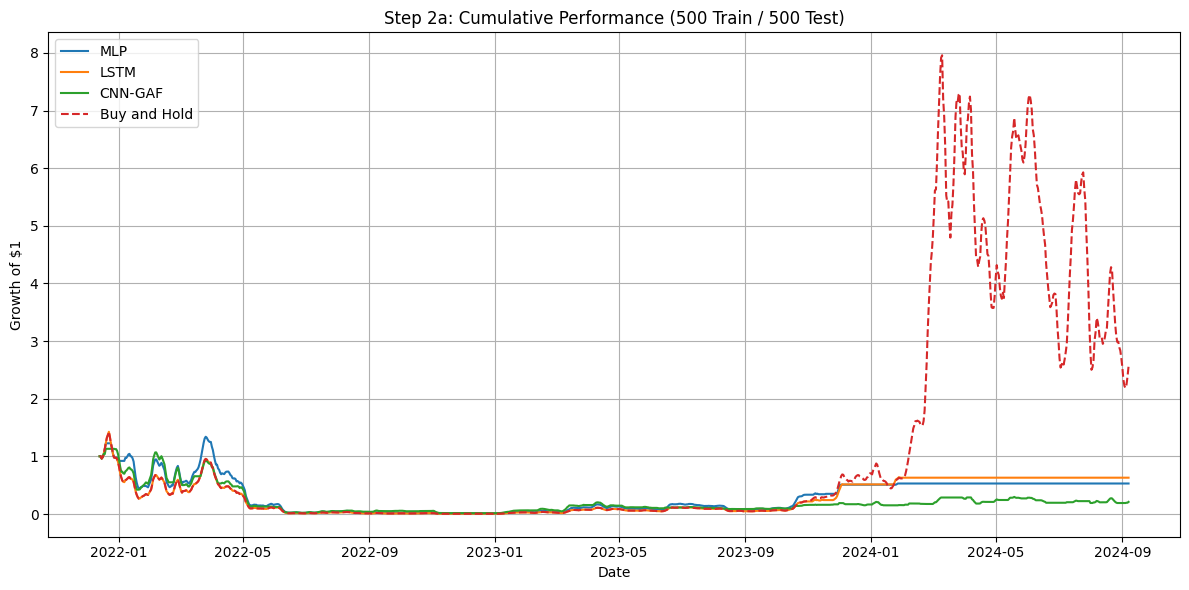


STEP 2a PREDICTION DISTRIBUTION

MLP
Number of predictions: 1000
Predicted 0: 320
Predicted 1: 680
Proportion predicted 1: 0.68

LSTM
Number of predictions: 1000
Predicted 0: 284
Predicted 1: 716
Proportion predicted 1: 0.716

CNN-GAF
Number of predictions: 1000
Predicted 0: 441
Predicted 1: 559
Proportion predicted 1: 0.559

Actual target distribution - Step 2a
0    495
1    505
Name: count, dtype: int64

STEP 2b: 500 TRAIN / 100 TEST

Running fold 1 of 14 (14 total)


MLP accuracy: 0.5
LSTM accuracy: 0.53
CNN-GAF accuracy: 0.46

Running fold 2 of 14 (14 total)
MLP accuracy: 0.36
LSTM accuracy: 0.4
CNN-GAF accuracy: 0.53

Running fold 3 of 14 (14 total)
MLP accuracy: 0.53
LSTM accuracy: 0.53
CNN-GAF accuracy: 0.41

Running fold 4 of 14 (14 total)
MLP accuracy: 0.58
LSTM accuracy: 0.57
CNN-GAF accuracy: 0.45

Running fold 5 of 14 (14 total)
MLP accuracy: 0.49
LSTM accuracy: 0.47
CNN-GAF accuracy: 0.46

Running fold 6 of 14 (14 total)
MLP accuracy: 0.4
LSTM accuracy: 0.4
CNN-GAF accuracy: 0.48

Running fold 7 of 14 (14 total)
MLP accuracy: 0.57
LSTM accuracy: 0.55
CNN-GAF accuracy: 0.51

Running fold 8 of 14 (14 total)
MLP accuracy: 0.44
LSTM accuracy: 0.44
CNN-GAF accuracy: 0.44

Running fold 9 of 14 (14 total)
MLP accuracy: 0.56
LSTM accuracy: 0.57
CNN-GAF accuracy: 0.52

Running fold 10 of 14 (14 total)
MLP accuracy: 0.5
LSTM accuracy: 0.4
CNN-GAF accuracy: 0.48

Running fold 11 of 14 (14 total)
MLP accuracy: 0.56
LSTM accuracy: 0.58
CNN-GAF accurac

,Fold,Train Start,Train End,Test Start,Test End,MLP Accuracy,LSTM Accuracy,CNN-GAF Accuracy
0,1,2020-07-31,2021-12-12,2021-12-13,2022-03-22,0.50,0.53,0.46
1,2,2020-11-08,2022-03-22,2022-03-23,2022-06-30,0.36,0.40,0.53
2,3,2021-02-16,2022-06-30,2022-07-01,2022-10-08,0.53,0.53,0.41
3,4,2021-05-27,2022-10-08,2022-10-09,2023-01-16,0.58,0.57,0.45
4,5,2021-09-04,2023-01-16,2023-01-17,2023-04-26,0.49,0.47,0.46
5,6,2021-12-13,2023-04-26,2023-04-27,2023-08-04,0.40,0.40,0.48
6,7,2022-03-23,2023-08-04,2023-08-05,2023-11-12,0.57,0.55,0.51
7,8,2022-07-01,2023-11-12,2023-11-13,2024-02-20,0.44,0.44,0.44
8,9,2022-10-09,2024-02-20,2024-02-21,2024-05-30,0.56,0.57,0.52
9,10,2023-01-17,2024-05-30,2024-05-31,2024-09-07,0.50,0.40,0.48



Step 2b Backtest Results:


,Strategy,Total Return,Annualized Return,Sharpe Ratio,Maximum Drawdown
0,MLP,801.77%,48.57%,0.912,-98.86%
1,LSTM,156.16%,18.45%,0.604,-99.54%
2,CNN-GAF,4.28%,0.76%,0.364,-99.32%
3,Buy and Hold,6992.57%,115.35%,1.280,-99.66%


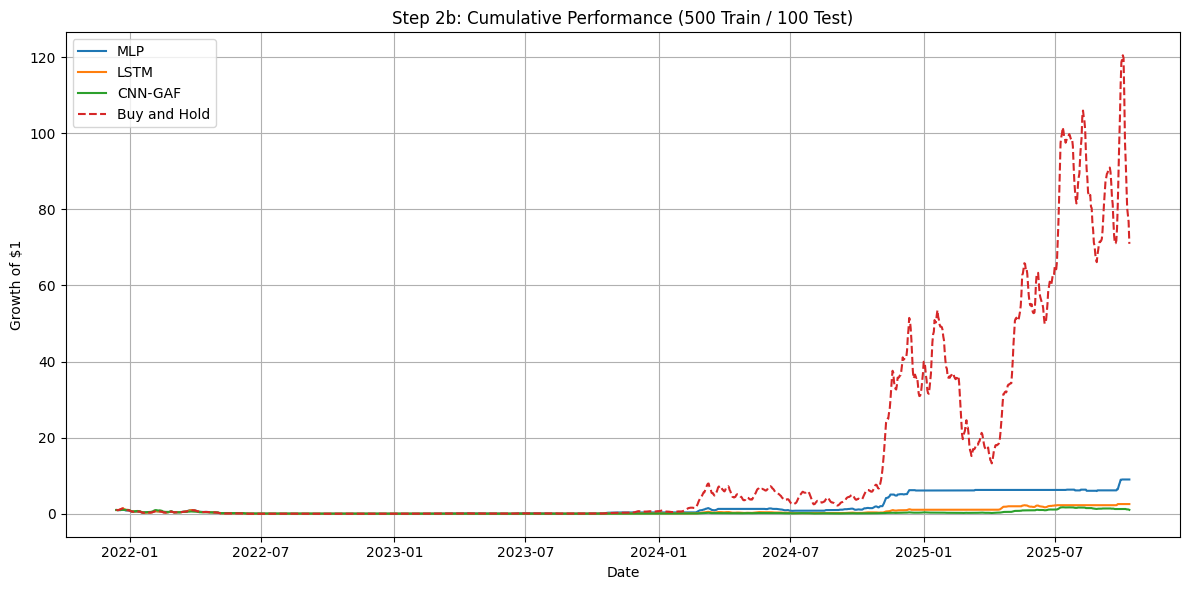


STEP 2b PREDICTION DISTRIBUTION

MLP
Number of predictions: 1400
Predicted 0: 795
Predicted 1: 605
Proportion predicted 1: 0.4321

LSTM
Number of predictions: 1400
Predicted 0: 688
Predicted 1: 712
Proportion predicted 1: 0.5086

CNN-GAF
Number of predictions: 1400
Predicted 0: 630
Predicted 1: 770
Proportion predicted 1: 0.55

Actual target distribution - Step 2b
0    663
1    737
Name: count, dtype: int64

STEP 2 PREDICTIVE ACCURACY COMPARISON


,Model,Step 2a Accuracy,Step 2b Accuracy
0,MLP,49.10%,49.57%
1,LSTM,49.50%,49.64%
2,CNN-GAF,47.40%,49.21%



STEP 2 INVESTMENT PERFORMANCE COMPARISON


,Strategy,Step 2a Total Return,Step 2b Total Return,Step 2a Sharpe,Step 2b Sharpe
0,MLP,-46.96%,801.77%,0.268,0.912
1,LSTM,-36.88%,156.16%,0.329,0.604
2,CNN-GAF,-78.86%,4.28%,-0.059,0.364
3,Buy and Hold,156.13%,6992.57%,0.751,1.280



STEP 2 SUMMARY

Step 2a uses a fixed 500-observation training window followed by a 500-observation test window.
Step 2a complete folds: 2

Step 2b uses a fixed 500-observation training window followed by a 100-observation test window.
Step 2b complete folds: 14

The training window is non-anchored because it moves forward through time while retaining a fixed length of 500 observations.

The same deliberately leaked labels used in Step 1 are retained. Therefore, Step 2 does not remove information leakage; it changes the validation design.

Step 2a and Step 2b should be compared with the Step 1 single-split results to evaluate whether the apparent performance is stable under walk-forward validation.


In [2]:
print("\n================================================")
print("STEP 2 SUMMARY")
print("================================================")


print(
    "\nStep 2a uses a fixed 500-observation training "
    "window followed by a 500-observation test window."
)


print(
    "Step 2a complete folds:",
    len(folds_500_500)
)


print(
    "\nStep 2b uses a fixed 500-observation training "
    "window followed by a 100-observation test window."
)


print(
    "Step 2b complete folds:",
    len(folds_500_100)
)


print(
    "\nThe training window is non-anchored because it "
    "moves forward through time while retaining a fixed "
    "length of 500 observations."
)


print(
    "\nThe same deliberately leaked labels used in Step 1 "
    "are retained. Therefore, Step 2 does not remove "
    "information leakage; it changes the validation design."
)


print(
    "\nStep 2a and Step 2b should be compared with the "
    "Step 1 single-split results to evaluate whether the "
    "apparent performance is stable under walk-forward "
    "validation."
)


# END OF STEP 2


## Walk-Forward Backtesting With Leakage Mitigation


In [ ]:
# (PURGING + EMBARGO)
#
# Important:


## Reuse of Prepared Features and Labels


In [ ]:
#   sample_dates, WINDOW, HORIZON, feature_columns, folds_500_500,
#   folds_500_100, and the model-building / metric functions
#   defined in Step 2).
# - The fold boundaries (train_start/train_end/test_start/test_end)
#   are kept IDENTICAL to Step 2, so that Step 2 and Step 3 are
#   comparable on the same dates. What changes is which training
#   observations inside that window are actually used to fit
#   each model.


print("\n================================================")
print("WALK-FORWARD BACKTESTING WITH LEAKAGE MITIGATION")
print("================================================")


## Leakage Mitigation with Purging and Embargo


In [ ]:
print("\nStep 3a. We describe a method to reduce leakage between "
      "training and test samples.")

print(
    "\nEach sample at position i in X_raw/y uses a feature window of "
    f"the previous {WINDOW} days and a target label built from the "
    f"forward {HORIZON}-day return. This means the label of a sample "
    "is only fully known once price data up to i + HORIZON have been "
    "observed. In Steps 1 and 2, training samples located near the "
    "train/test boundary have label windows that extend past the end "
    "of the training block and into the test block. Any model that "
    "trains on those samples has effectively 'seen' price information "
    "from inside the test period through the label, which is the "
    "leakage this analysis isolates."
)

print(
    "\nWe mitigate this with the purging and embargo procedure "
    "described in Lopez de Prado (2018), adapted to a single "
    "walk-forward boundary:"
)

print(
    "\n(1) Purging: any training sample whose forward-return label "
    "window [i, i + HORIZON] overlaps the first test observation is "
    "removed from the training set. Because labels are built HORIZON "
    "steps ahead, this means dropping the last HORIZON samples at the "
    "end of every training fold."
)

print(
    "\n(2) Embargo: even after purging, samples immediately before "
    "the test period can still be informative about the test period "
    "through short-term serial correlation in returns and volatility. "
    "We therefore drop an additional EMBARGO samples from the end of "
    "the training fold, on top of the purge, before training begins. "
    "The test set itself is left untouched, so the comparison with "
    "Step 2 is on identical test dates."
)

PURGE = HORIZON
EMBARGO = HORIZON

print(
    f"\nPurge length: {PURGE} observations (equal to the label "
    f"horizon). Embargo length: {EMBARGO} observations (an additional "
    "buffer of the same size, chosen conservatively so the total gap "
    f"between the last usable training label and the first test "
    f"observation is {PURGE + EMBARGO} days). Together, the effective "
    f"training window shrinks from {TRAIN_SIZE} to "
    f"{TRAIN_SIZE - PURGE - EMBARGO} observations per fold; the test "
    "windows are unchanged from Step 2."
)


## Purged + Embargoed Walk-Forward Function


In [ ]:
#
# This reuses build_mlp, build_lstm, build_cnn_gaf and
# calculate_strategy_metrics / create_backtest_table from Step 2.
# The only change versus run_walk_forward (Step 2) is that the
# training slice for each fold drops the last (purge + embargo)
# observations before scaling and fitting.

def run_walk_forward_purged(
    X_raw,
    y,
    future_returns,
    sample_dates,
    folds,
    purge=PURGE,
    embargo=EMBARGO,
    verbose=False
):

    all_predictions = {"MLP": [], "LSTM": [], "CNN-GAF": []}
    all_actual = []
    all_returns = []
    all_dates = []
    fold_results = []

    feature_count = len(feature_columns)
    gap = purge + embargo

    for fold_number, fold in enumerate(folds, start=1):

        print(f"\nRunning fold {fold_number} of {len(folds)} "
              f"({len(folds)} total) -- purge={purge}, embargo={embargo}")

        train_start = fold["train_start"]
        train_end = fold["train_end"]
        test_start = fold["test_start"]
        test_end = fold["test_end"]

        # Drop the last (purge + embargo) observations from the
        # training block. The test block is untouched.
        train_end_purged = train_end - gap

        if train_end_purged <= train_start:
            print("Skipping fold: purge + embargo leaves no "
                  "training observations.")
            continue

        X_train_raw = X_raw[train_start:train_end_purged]
        X_test_raw = X_raw[test_start:test_end]

        y_train = y[train_start:train_end_purged]
        y_test = y[test_start:test_end]

        returns_test = future_returns[test_start:test_end]

        dates_train = sample_dates[train_start:train_end_purged]
        dates_test = sample_dates[test_start:test_end]

        # Scale (fit on the purged/embargoed training data only)
        scaler_fold = StandardScaler()

        X_train_2d = X_train_raw.reshape(-1, feature_count)
        X_test_2d = X_test_raw.reshape(-1, feature_count)

        scaler_fold.fit(X_train_2d)

        X_train_scaled = scaler_fold.transform(X_train_2d).reshape(X_train_raw.shape)
        X_test_scaled = scaler_fold.transform(X_test_2d).reshape(X_test_raw.shape)

        # MLP
        X_train_mlp = X_train_scaled.reshape(X_train_scaled.shape[0], -1)
        X_test_mlp = X_test_scaled.reshape(X_test_scaled.shape[0], -1)

        mlp_model = build_mlp((X_train_mlp.shape[1],))
        mlp_model.fit(
            X_train_mlp, y_train,
            epochs=20, batch_size=32,
            validation_split=0.20, shuffle=False, verbose=0
        )
        mlp_prob = mlp_model.predict(X_test_mlp, verbose=0).ravel()
        mlp_pred = (mlp_prob >= 0.50).astype(int)
        mlp_accuracy = accuracy_score(y_test, mlp_pred)

        # LSTM
        lstm_model = build_lstm((WINDOW, feature_count))
        lstm_model.fit(
            X_train_scaled, y_train,
            epochs=20, batch_size=32,
            validation_split=0.20, shuffle=False, verbose=0
        )
        lstm_prob = lstm_model.predict(X_test_scaled, verbose=0).ravel()
        lstm_pred = (lstm_prob >= 0.50).astype(int)
        lstm_accuracy = accuracy_score(y_test, lstm_pred)

        # CNN-GAF
        gaf_fold = GramianAngularField(image_size=WINDOW, method="summation")

        close_train = X_train_raw[:, :, 3]
        close_test = X_test_raw[:, :, 3]

        X_train_gaf = gaf_fold.fit_transform(close_train)[..., np.newaxis]
        X_test_gaf = gaf_fold.transform(close_test)[..., np.newaxis]

        cnn_model = build_cnn_gaf(X_train_gaf.shape[1:])
        cnn_model.fit(
            X_train_gaf, y_train,
            epochs=20, batch_size=32,
            validation_split=0.20, shuffle=False, verbose=0
        )
        cnn_prob = cnn_model.predict(X_test_gaf, verbose=0).ravel()
        cnn_pred = (cnn_prob >= 0.50).astype(int)
        cnn_accuracy = accuracy_score(y_test, cnn_pred)

        # Store results
        all_predictions["MLP"].extend(mlp_pred.tolist())
        all_predictions["LSTM"].extend(lstm_pred.tolist())
        all_predictions["CNN-GAF"].extend(cnn_pred.tolist())

        all_actual.extend(y_test.tolist())
        all_returns.extend(returns_test.tolist())
        all_dates.extend(dates_test.tolist())

        fold_results.append({
            "Fold": fold_number,
            "Train Start": dates_train[0],
            "Train End": dates_train[-1],
            "Test Start": dates_test[0],
            "Test End": dates_test[-1],
            "Effective Train Size": len(dates_train),
            "MLP Accuracy": mlp_accuracy,
            "LSTM Accuracy": lstm_accuracy,
            "CNN-GAF Accuracy": cnn_accuracy
        })

        if verbose:
            print("MLP accuracy:", round(mlp_accuracy, 4))
            print("LSTM accuracy:", round(lstm_accuracy, 4))
            print("CNN-GAF accuracy:", round(cnn_accuracy, 4))

        del mlp_model, lstm_model, cnn_model
        try:
            tf.keras.backend.clear_session()
        except:
            pass

    return (
        all_predictions,
        np.array(all_actual),
        np.array(all_returns),
        np.array(all_dates),
        pd.DataFrame(fold_results)
    )


## Purged Evaluation: 500-Observation Train and Test Windows


In [ ]:
print("\n================================================")
print("500 TRAIN / 500 TEST (PURGED + EMBARGOED)")
print("================================================")

results_500_500_purged = run_walk_forward_purged(
    X_raw=X_raw,
    y=y,
    future_returns=future_returns,
    sample_dates=sample_dates,
    folds=folds_500_500,
    verbose=True
)

predictions_500_500_purged = results_500_500_purged[0]
actual_500_500_purged = results_500_500_purged[1]
returns_500_500_purged = results_500_500_purged[2]
dates_500_500_purged = results_500_500_purged[3]
fold_accuracy_500_500_purged = results_500_500_purged[4]

print("\nStep 3b fold accuracy (purged + embargoed):")
display(fold_accuracy_500_500_purged.round(4))

backtest_500_500_purged = create_backtest_table(
    predictions_500_500_purged,
    returns_500_500_purged
)

print("\nStep 3b Backtest Results:")
display(
    backtest_500_500_purged.style.format({
        "Total Return": "{:.2%}",
        "Annualized Return": "{:.2%}",
        "Sharpe Ratio": "{:.3f}",
        "Maximum Drawdown": "{:.2%}"
    })
)

plt.figure(figsize=(12, 6))
for model_name, predictions in predictions_500_500_purged.items():
    predictions = np.asarray(predictions)
    strategy_returns = np.where(predictions == 1, returns_500_500_purged, 0.0)
    equity_curve = np.cumprod(1 + strategy_returns)
    plt.plot(dates_500_500_purged, equity_curve, label=model_name)

buy_hold_equity_purged_500 = np.cumprod(1 + returns_500_500_purged)
plt.plot(dates_500_500_purged, buy_hold_equity_purged_500,
          label="Buy and Hold", linestyle="--")
plt.title("Cumulative Performance (500 Train / 500 Test, Purged + Embargoed)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Purged Evaluation: 500-Observation Train and 100-Observation Test Windows


In [ ]:
print("\n================================================")
print("500 TRAIN / 100 TEST (PURGED + EMBARGOED)")
print("================================================")

results_500_100_purged = run_walk_forward_purged(
    X_raw=X_raw,
    y=y,
    future_returns=future_returns,
    sample_dates=sample_dates,
    folds=folds_500_100,
    verbose=True
)

predictions_500_100_purged = results_500_100_purged[0]
actual_500_100_purged = results_500_100_purged[1]
returns_500_100_purged = results_500_100_purged[2]
dates_500_100_purged = results_500_100_purged[3]
fold_accuracy_500_100_purged = results_500_100_purged[4]

print("\nStep 3c fold accuracy (purged + embargoed):")
display(fold_accuracy_500_100_purged.round(4))

backtest_500_100_purged = create_backtest_table(
    predictions_500_100_purged,
    returns_500_100_purged
)

print("\nStep 3c Backtest Results:")
display(
    backtest_500_100_purged.style.format({
        "Total Return": "{:.2%}",
        "Annualized Return": "{:.2%}",
        "Sharpe Ratio": "{:.3f}",
        "Maximum Drawdown": "{:.2%}"
    })
)

plt.figure(figsize=(12, 6))
for model_name, predictions in predictions_500_100_purged.items():
    predictions = np.asarray(predictions)
    strategy_returns = np.where(predictions == 1, returns_500_100_purged, 0.0)
    equity_curve = np.cumprod(1 + strategy_returns)
    plt.plot(dates_500_100_purged, equity_curve, label=model_name)

buy_hold_equity_purged_100 = np.cumprod(1 + returns_500_100_purged)
plt.plot(dates_500_100_purged, buy_hold_equity_purged_100,
          label="Buy and Hold", linestyle="--")
plt.title("Cumulative Performance (500 Train / 100 Test, Purged + Embargoed)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Compare Leakage-Controlled and Baseline Results


In [ ]:
print("\n================================================")
print("STEP 3d. Comparing results across validation designs")
print("================================================")

step3_accuracy_comparison = pd.DataFrame({
    "Model": ["MLP", "LSTM", "CNN-GAF"],
    "Step 3b Accuracy": [
        accuracy_score(actual_500_500_purged, predictions_500_500_purged["MLP"]),
        accuracy_score(actual_500_500_purged, predictions_500_500_purged["LSTM"]),
        accuracy_score(actual_500_500_purged, predictions_500_500_purged["CNN-GAF"])
    ],
    "Step 3c Accuracy": [
        accuracy_score(actual_500_100_purged, predictions_500_100_purged["MLP"]),
        accuracy_score(actual_500_100_purged, predictions_500_100_purged["LSTM"]),
        accuracy_score(actual_500_100_purged, predictions_500_100_purged["CNN-GAF"])
    ]
})

print("\nStep 3 predictive accuracy comparison (3b vs 3c):")
display(step3_accuracy_comparison.style.format({
    "Step 3b Accuracy": "{:.2%}",
    "Step 3c Accuracy": "{:.2%}"
}))

# Side-by-side comparison of Step 2 (leaked) vs Step 3 (purged)
# for each matching configuration.

leakage_effect_table = pd.DataFrame({
    "Model": ["MLP", "LSTM", "CNN-GAF"],

    "Step 2a Accuracy (500/500, leaked)": [
        accuracy_score(actual_500_500, predictions_500_500["MLP"]),
        accuracy_score(actual_500_500, predictions_500_500["LSTM"]),
        accuracy_score(actual_500_500, predictions_500_500["CNN-GAF"])
    ],
    "Step 3b Accuracy (500/500, purged)": [
        accuracy_score(actual_500_500_purged, predictions_500_500_purged["MLP"]),
        accuracy_score(actual_500_500_purged, predictions_500_500_purged["LSTM"]),
        accuracy_score(actual_500_500_purged, predictions_500_500_purged["CNN-GAF"])
    ],

    "Step 2b Accuracy (500/100, leaked)": [
        accuracy_score(actual_500_100, predictions_500_100["MLP"]),
        accuracy_score(actual_500_100, predictions_500_100["LSTM"]),
        accuracy_score(actual_500_100, predictions_500_100["CNN-GAF"])
    ],
    "Step 3c Accuracy (500/100, purged)": [
        accuracy_score(actual_500_100_purged, predictions_500_100_purged["MLP"]),
        accuracy_score(actual_500_100_purged, predictions_500_100_purged["LSTM"]),
        accuracy_score(actual_500_100_purged, predictions_500_100_purged["CNN-GAF"])
    ]
})

print("\nEffect of purging + embargo on predictive accuracy:")
display(leakage_effect_table.round(4))

# Same comparison on Sharpe ratio (the investment-relevant metric)

def get_sharpe(table, strategy):
    return table.loc[table["Strategy"] == strategy, "Sharpe Ratio"].iloc[0]

sharpe_comparison = pd.DataFrame({
    "Strategy": ["MLP", "LSTM", "CNN-GAF", "Buy and Hold"],

    "Step 2a Sharpe (500/500, leaked)": [
        get_sharpe(backtest_500_500, s) for s in
        ["MLP", "LSTM", "CNN-GAF", "Buy and Hold"]
    ],
    "Step 3b Sharpe (500/500, purged)": [
        get_sharpe(backtest_500_500_purged, s) for s in
        ["MLP", "LSTM", "CNN-GAF", "Buy and Hold"]
    ],
    "Step 2b Sharpe (500/100, leaked)": [
        get_sharpe(backtest_500_100, s) for s in
        ["MLP", "LSTM", "CNN-GAF", "Buy and Hold"]
    ],
    "Step 3c Sharpe (500/100, purged)": [
        get_sharpe(backtest_500_100_purged, s) for s in
        ["MLP", "LSTM", "CNN-GAF", "Buy and Hold"]
    ]
})

print("\nEffect of purging + embargo on Sharpe ratio:")
display(sharpe_comparison.round(3))

# Automatic, data-driven interpretation.
# These sentences are generated from the actual numbers above,
# so they stay correct however the run turns out.

acc_drop_500 = (
    leakage_effect_table["Step 2a Accuracy (500/500, leaked)"].mean()
    - leakage_effect_table["Step 3b Accuracy (500/500, purged)"].mean()
)

acc_drop_100 = (
    leakage_effect_table["Step 2b Accuracy (500/100, leaked)"].mean()
    - leakage_effect_table["Step 3c Accuracy (500/100, purged)"].mean()
)

print(
    f"\nOn average across the three models, accuracy on the "
    f"500/500 configuration {'fell' if acc_drop_500 > 0 else 'rose'} "
    f"by {abs(acc_drop_500):.2%} once purging and embargo were applied "
    f"(> Step 3b), and {'fell' if acc_drop_100 > 0 else 'rose'} "
    f"by {abs(acc_drop_100):.2%} on the 500/100 configuration "
    f"(> Step 3c)."
)

print(
    "\nIf accuracy and Sharpe ratios decline once the leaked "
    "labels near the train/test boundary are purged and an embargo "
    "is enforced, this indicates that part of the apparent predictive "
    "power measured in Steps 1 and 2 was attributable to information "
    "leakage rather than to genuine forecasting ability. Overfitting "
    "to the leakage would then be considered to have 'disappeared' "
    "once results here converge toward the buy-and-hold benchmark or "
    "toward a Sharpe ratio close to zero. If, instead, performance is "
    "materially unchanged after purging and embargo, that is evidence "
    "the models were not relying on the leaked boundary observations "
    "and that the walk-forward performance in Step 2 was reasonably "
    "robust."
)

print(
    "\nComparing Step 3b (500/500) with Step 3c (500/100) isolates "
    "the effect of test-window length once leakage has been "
    "controlled for: a shorter, more frequently retrained test window "
    "(Step 3c) re-estimates the model more often and reacts faster to "
    "regime changes, but each individual test segment is noisier "
    "because it is evaluated on fewer observations. A material gap "
    "between Step 3b and Step 3c that was not present between Step 2a "
    "and Step 2b would suggest the retraining frequency itself, not "
    "just the leakage, is influencing the backtest."
)


## Leakage-Controlled Validation Summary



STEP 3: WALK-FORWARD BACKTESTING WITH LEAKAGE MITIGATION

Step 3a. We describe a method to reduce leakage between training and test samples.

Each sample at position i in X_raw/y uses a feature window of the previous 20 days and a target label built from the forward 5-day return. This means the label of a sample is only fully known once price data up to i + HORIZON have been observed. In Steps 1 and 2, training samples located near the train/test boundary have label windows that extend past the end of the training block and into the test block. Any model that trains on those samples has effectively 'seen' price information from inside the test period through the label, which is the leakage the assignment asks us to isolate.

We mitigate this with the purging and embargo procedure described in Lopez de Prado (2018), adapted to a single walk-forward boundary:

(1) Purging: any training sample whose forward-return label window [i, i + HORIZON] overlaps the first test observation is remov

,Fold,Train Start,Train End,Test Start,Test End,Effective Train Size,MLP Accuracy,LSTM Accuracy,CNN-GAF Accuracy
0,1,2020-07-31,2021-12-02,2021-12-13,2023-04-26,490,0.534,0.514,0.48
1,2,2021-12-13,2023-04-16,2023-04-27,2024-09-07,490,0.490,0.532,0.48



Step 3b Backtest Results:


,Strategy,Total Return,Annualized Return,Sharpe Ratio,Maximum Drawdown
0,MLP,109.06%,20.42%,0.649,-98.56%
1,LSTM,385.46%,48.91%,0.899,-99.33%
2,CNN-GAF,-87.89%,-41.26%,-0.210,-99.71%
3,Buy and Hold,156.13%,26.75%,0.751,-99.66%


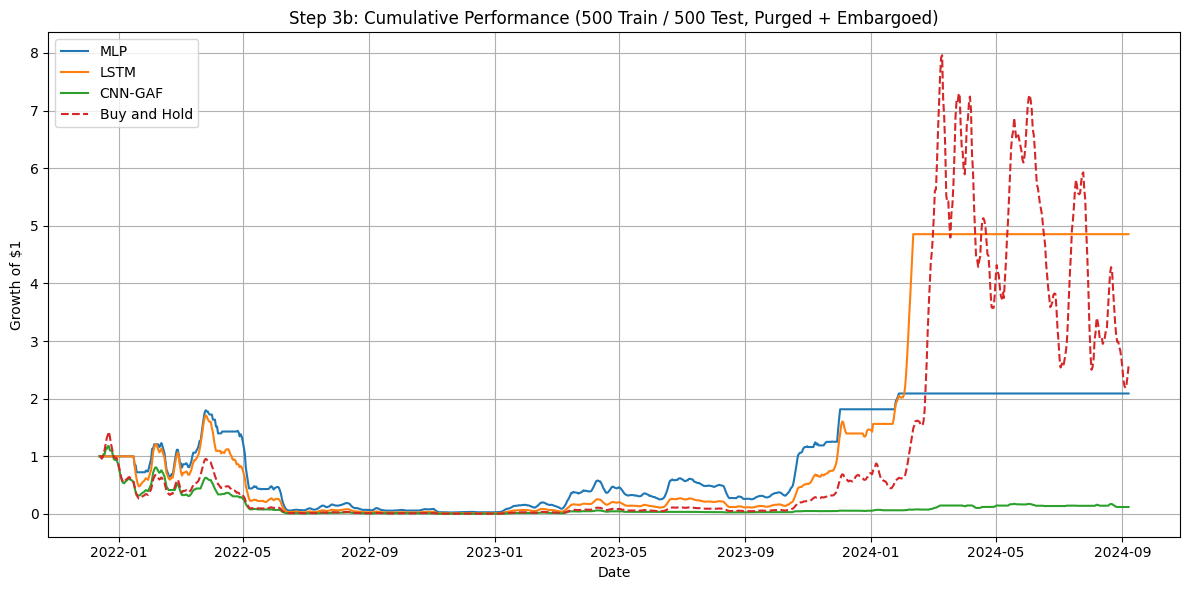


STEP 3c: 500 TRAIN / 100 TEST (PURGED + EMBARGOED)

Running fold 1 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.59
LSTM accuracy: 0.57
CNN-GAF accuracy: 0.51

Running fold 2 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.37
LSTM accuracy: 0.36
CNN-GAF accuracy: 0.51

Running fold 3 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.53
LSTM accuracy: 0.52
CNN-GAF accuracy: 0.43

Running fold 4 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.55
LSTM accuracy: 0.6
CNN-GAF accuracy: 0.44

Running fold 5 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.47
LSTM accuracy: 0.5
CNN-GAF accuracy: 0.52

Running fold 6 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.41
LSTM accuracy: 0.4
CNN-GAF accuracy: 0.38

Running fold 7 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.41
LSTM accuracy: 0.42
CNN-GAF accuracy: 0.52

Running fold 8 of 14 (14 total) -- purge=5, embargo=5
MLP accuracy: 0.44
LSTM accuracy: 0.44
CNN-GAF accuracy: 0.46

Running fold 9

,Fold,Train Start,Train End,Test Start,Test End,Effective Train Size,MLP Accuracy,LSTM Accuracy,CNN-GAF Accuracy
0,1,2020-07-31,2021-12-02,2021-12-13,2022-03-22,490,0.59,0.57,0.51
1,2,2020-11-08,2022-03-12,2022-03-23,2022-06-30,490,0.37,0.36,0.51
2,3,2021-02-16,2022-06-20,2022-07-01,2022-10-08,490,0.53,0.52,0.43
3,4,2021-05-27,2022-09-28,2022-10-09,2023-01-16,490,0.55,0.60,0.44
4,5,2021-09-04,2023-01-06,2023-01-17,2023-04-26,490,0.47,0.50,0.52
5,6,2021-12-13,2023-04-16,2023-04-27,2023-08-04,490,0.41,0.40,0.38
6,7,2022-03-23,2023-07-25,2023-08-05,2023-11-12,490,0.41,0.42,0.52
7,8,2022-07-01,2023-11-02,2023-11-13,2024-02-20,490,0.44,0.44,0.46
8,9,2022-10-09,2024-02-10,2024-02-21,2024-05-30,490,0.60,0.57,0.51
9,10,2023-01-17,2024-05-20,2024-05-31,2024-09-07,490,0.47,0.55,0.52



Step 3c Backtest Results:


,Strategy,Total Return,Annualized Return,Sharpe Ratio,Maximum Drawdown
0,MLP,350.31%,31.11%,0.743,-98.86%
1,LSTM,2139.44%,74.99%,1.128,-99.40%
2,CNN-GAF,82.98%,11.49%,0.521,-99.02%
3,Buy and Hold,6992.57%,115.35%,1.280,-99.66%


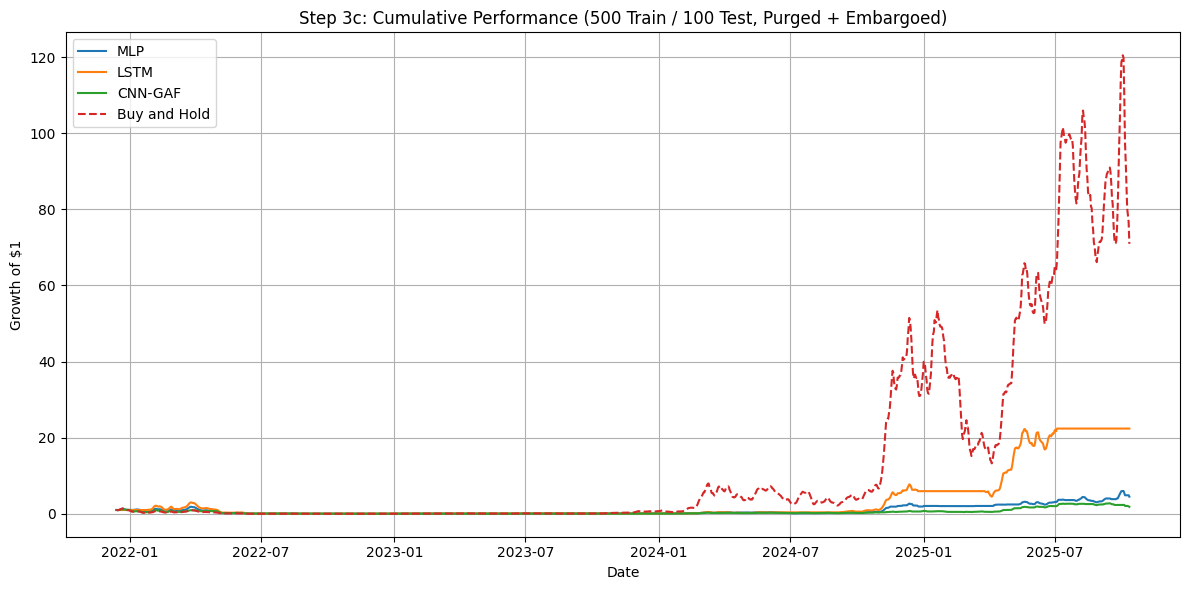


STEP 3d. Comparing results across validation designs

Step 3 predictive accuracy comparison (3b vs 3c):


,Model,Step 3b Accuracy,Step 3c Accuracy
0,MLP,51.20%,49.71%
1,LSTM,52.30%,51.86%
2,CNN-GAF,48.00%,49.64%



Effect of purging + embargo on predictive accuracy:


,Model,"Step 2a Accuracy (500/500, leaked)","Step 3b Accuracy (500/500, purged)","Step 2b Accuracy (500/100, leaked)","Step 3c Accuracy (500/100, purged)"
0,MLP,0.491,0.512,0.4957,0.4971
1,LSTM,0.495,0.523,0.4964,0.5186
2,CNN-GAF,0.474,0.480,0.4921,0.4964



Effect of purging + embargo on Sharpe ratio:


,Strategy,"Step 2a Sharpe (500/500, leaked)","Step 3b Sharpe (500/500, purged)","Step 2b Sharpe (500/100, leaked)","Step 3c Sharpe (500/100, purged)"
0,MLP,0.268,0.649,0.912,0.743
1,LSTM,0.329,0.899,0.604,1.128
2,CNN-GAF,-0.059,-0.210,0.364,0.521
3,Buy and Hold,0.751,0.751,1.280,1.280



On average across the three models, accuracy on the 500/500 configuration rose by 1.83% once purging and embargo were applied (Step 2a -> Step 3b), and rose by 0.93% on the 500/100 configuration (Step 2b -> Step 3c).

If accuracy and Sharpe ratios decline once the leaked labels near the train/test boundary are purged and an embargo is enforced, this indicates that part of the apparent predictive power measured in Steps 1 and 2 was attributable to information leakage rather than to genuine forecasting ability. Overfitting to the leakage would then be considered to have 'disappeared' once results here converge toward the buy-and-hold benchmark or toward a Sharpe ratio close to zero. If, instead, performance is materially unchanged after purging and embargo, that is evidence the models were not relying on the leaked boundary observations and that the walk-forward performance in Step 2 was reasonably robust.

Comparing Step 3b (500/500) with Step 3c (500/100) isolates the effect of test-w

In [3]:
print("\n================================================")
print("STEP 3 SUMMARY")
print("================================================")

print(
    f"\nStep 3 repeats the Step 2 walk-forward folds with the same "
    f"train/test boundaries, but drops the last {PURGE} training "
    f"observations (purge, to remove labels overlapping the test "
    f"period) and a further {EMBARGO} training observations (embargo, "
    "as a serial-correlation buffer) from every training fold before "
    "fitting each model."
)

print(
    "\nStep 3b uses the same 500-observation training block and "
    "500-observation test block as Step 2a, with purging and embargo "
    "applied to training only."
)

print(
    "\nStep 3c uses the same 500-observation training block and "
    "100-observation test block as Step 2b, with purging and embargo "
    "applied to training only."
)

print(
    "\nStep 3 results should be read alongside Step 1 (single leaked "
    "split) and Step 2 (walk-forward, still leaked) to assess how "
    "much of the apparent predictive edge in the earlier steps was "
    "an artifact of the leakage in the label construction, rather "
    "than genuine out-of-sample forecasting skill."
)

# END OF STEP 3

print("\nStep 3 completed.")
